# RSM 02 · Yield and productivity in a selective CSTR

**Chemical Engineering Modelling Labs · Worked teaching edition**

**Advanced case · four independent inputs.** Approximate nonlinear reactor behaviour, preserve algebraic response identities and examine an engineering trade-off before checking extrapolation.

## Start here · use in Google Colab
Open this `.ipynb` with **File → Upload notebook**, keep a **CPU runtime**, and use **Runtime → Run all**. Save an individual copy before editing. All data are generated inside the notebook; the core exercise needs no upload, process simulator, API key, GPU or Julia installation.

Every executable line has an adjacent English comment. Markdown between cells explains the scientific purpose and the result to inspect. Saved tables and plots are retained in this worked edition so that it is also readable without running it.

**Teaching contract.** These are synthetic observations, not laboratory measurements. Ground truth is disclosed for teaching and independent audits; model fitting uses noisy training targets only. Validation selects a model; test and challenge sets report performance after selection. Repeatedly redesigning a model after reading test errors invalidates the original test.

**Follow the sequence:** context → data → model structure → fitting → validation → test diagnostics → engineering interpretation → exercises → export.

## 1. Set up Python

In [1]:
import importlib.util  # Check the runtime before installing any packages.
import subprocess  # Run pip through this notebook's Python interpreter when required.
import sys  # Identify the active interpreter and record its version.
requirements = {'numpy': 'numpy', 'pandas': 'pandas', 'matplotlib': 'matplotlib', 'scipy': 'scipy', 'statsmodels': 'statsmodels', 'sklearn': 'scikit-learn', 'sympy': 'sympy'}  # Map Python imports to package names.
missing = [package for module, package in requirements.items() if importlib.util.find_spec(module) is None]  # Find only the dependencies that are absent.
if missing:  # Keep a working Colab environment unchanged whenever possible.
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])  # Install missing packages in the current runtime.
import numpy as np  # Perform numerical array calculations and generate controlled random noise.
import pandas as pd  # Display labelled datasets and result tables.
import matplotlib.pyplot as plt  # Create figures with the default Matplotlib colours.
import scipy  # Record the numerical-library version for reproducibility.
from scipy import stats  # Obtain statistical distributions and diagnostics.
from scipy.optimize import minimize, least_squares  # Optimise operating points and fit nonlinear equation parameters.
import statsmodels.api as sm  # Fit linear-in-coefficient regressions and estimate statistical intervals.
from sklearn.preprocessing import PolynomialFeatures  # Generate polynomial terms for the RSM baselines.
from itertools import combinations, product  # Enumerate experimental-design pairs and symbolic candidate structures.
from pathlib import Path  # Manage output files independently of the operating system.
import json  # Save fitted-model specifications in readable form.
import shutil  # Bundle figures and tables into a downloadable archive.
from IPython.display import display, Markdown, Math, FileLink  # Embed formatted tables, equations and links in the notebook.
plt.rcParams.update({'font.size': 11, 'axes.titlesize': 13, 'axes.labelsize': 11, 'figure.dpi': 110})  # Keep figure text legible without changing colour or plot style.
pd.set_option('display.max_columns', 16)  # Keep the important columns visible in result tables.
versions = pd.DataFrame({'component': ['Python', 'NumPy', 'pandas', 'SciPy', 'statsmodels'], 'version': [sys.version.split()[0], np.__version__, pd.__version__, scipy.__version__, sm.__version__]})  # Record the environment used for this execution.
display(versions)  # Show the software versions before modelling begins.

,component,version
0,Python,3.13.5
1,NumPy,2.3.5
2,pandas,2.2.3
3,SciPy,1.17.0
4,statsmodels,0.14.6


**Checkpoint.** The version table should appear without an exception. Core dependencies are installed only when absent. Minor numerical differences between package versions are possible.

In [2]:
SEED = 20261010  # Reproduce the original four-case teaching dataset package.
case_seed = np.random.SeedSequence(SEED).spawn(4)[1]  # Select an independent random stream for this chemical-engineering case.
design_seed, noise_seed = case_seed.spawn(2)  # Keep operating-point sampling separate from observation noise.
rng_design = np.random.default_rng(design_seed)  # Generate reproducible experimental conditions.
rng_noise = np.random.default_rng(noise_seed)  # Generate reproducible but independent measurement errors.
RESULTS = Path('results_02_rsm_selective_cstr')  # Store this case's figures, data and fitted-model files in one place.
RESULTS.mkdir(exist_ok=True)  # Reuse the same folder safely when the notebook is rerun.
print('Output folder:', RESULTS.resolve())  # Identify the files that can be downloaded at the end.

Output folder: /mnt/data/Colab_Teaching_Notebooks/results_02_rsm_selective_cstr


**Reproducibility.** The default settings regenerate the corresponding observations in the earlier dataset package. Changing the seed represents a new synthetic experiment; do not choose a seed for favourable performance.

In [3]:
def lhs(n, bounds, rng):  # Spread observations across each input range using Latin hypercube sampling.
    bounds = np.asarray(bounds, dtype=float)  # Convert the physical lower and upper limits into an array.
    u = np.column_stack([(rng.permutation(n) + rng.random(n)) / n for _ in bounds])  # Sample every stratum once in each input direction.
    return bounds[:, 0] + u * (bounds[:, 1] - bounds[:, 0])  # Map the samples into the physical operating box.

def save_plot(fig, filename):  # Display and preserve each result figure.
    fig.tight_layout()  # Reduce crowding between labels, axes and titles.
    fig.savefig(RESULTS / (filename + '.png'), dpi=160, bbox_inches='tight')  # Save a high-resolution copy for teaching slides or reports.
    plt.show()  # Embed the figure in the notebook output.
    plt.close(fig)  # Release figure memory before continuing to the next plot.

def metrics(y, prediction):  # Quantify predictions without refitting the model.
    y, prediction = np.asarray(y), np.asarray(prediction)  # Ensure compatible numerical arrays.
    errors = prediction - y  # Define a positive error as an overprediction.
    return {'RMSE': float(np.sqrt(np.mean(errors**2))), 'MAE': float(np.mean(np.abs(errors))), 'R_squared': float(1 - np.sum(errors**2) / np.sum((y-y.mean())**2))}  # Return error magnitudes and the mean-response comparison.

def parity(y, prediction, title, units, filename):  # Compare new observations with fixed-model predictions.
    fig, ax = plt.subplots(figsize=(6.8, 5.2))  # Create a single readable plotting panel.
    ax.scatter(y, prediction, s=26, alpha=0.7)  # Draw one marker per independent evaluation observation.
    limits = [min(np.min(y), np.min(prediction)), max(np.max(y), np.max(prediction))]  # Cover observed and predicted values with the same numerical range.
    ax.plot(limits, limits, '--', label='Perfect prediction')  # Mark the identity line as the reference.
    ax.set(xlabel='Observed '+units, ylabel='Predicted '+units, title=title)  # State the response units and evaluation purpose.
    ax.legend()  # Identify the reference line without cluttering the plot.
    save_plot(fig, filename)  # Save and embed this parity figure.

**Read the helpers.** RMSE and MAE retain the response units. $R^2$ can be negative. A scatter plot is an evaluation tool, not proof of a valid mechanism.

## 2. Reactor context and governing equations
Consider lumped consecutive reactions $A\rightarrow B\rightarrow C$, where $B$ is the desired intermediate. Assume an isothermal, steady, constant-density CSTR, no $B$ or $C$ in fresh feed, and one-to-one lumped molar stoichiometry.

| Independent input | Training range |
|---|---:|
| Temperature, $T$ | 335–355 K |
| Residence time, $\tau$ | 1–5 min |
| Feed concentration, $C_{A0}$ | 0.5–1.5 mol L$^{-1}$ |
| Catalyst concentration, $c_{cat}$ | 0.5–1.5 g L$^{-1}$ |

Define $a=c_{cat}/(1\ \mathrm{g\,L^{-1}})$ and empirical rates
$$r_1=a k_1(T)C_A,\quad r_2=a k_2(T)C_B^2,$$
$$k_i(T)=k_{i,ref}\exp\left[-\frac{E_i}{R}\left(\frac1T-\frac1{345}\right)\right].$$
The teaching values are $k_{1,ref}=0.35\ \mathrm{min^{-1}}$, $k_{2,ref}=0.25\ \mathrm{L\,mol^{-1}\,min^{-1}}$, $E_1=35$ and $E_2=60$ kJ mol$^{-1}$. The second-order law is empirical; the lumped arrow is not an elementary molecular mechanism.

Steady balances give
$$C_A=\frac{C_{A0}}{1+\tau a k_1},\qquad \tau a k_2C_B^2+C_B-\tau a k_1C_A=0.$$
Use the positive root for $C_B$. Define feed-based yield and volumetric productivity:
$$Y_B=C_B/C_{A0},\qquad P_B=C_B/\tau.$$

**Noise belongs to the concentration measurement:** add $0.005\ \mathrm{mol\,L^{-1}}$ Gaussian standard deviation to $C_B$, then derive the two other responses. Their errors are therefore related. This generator is nonlinear, not another quadratic polynomial.

In [4]:
FEATURES = ['temperature_K', 'residence_time_min', 'feed_A_mol_L', 'catalyst_g_L']  # Name the four independent reactor inputs.
BOUNDS = np.array([[335, 355], [1, 5], [0.5, 1.5], [0.5, 1.5]], dtype=float)  # Define the design region in physical units.
CENTRE, HALF_RANGE = BOUNDS.mean(axis=1), np.diff(BOUNDS, axis=1).ravel()/2  # Fix the coded-input transformation from the experiment design.
R = 8.314462618  # Use the molar gas constant in joules per mole per kelvin.
NOISE_SD = 0.005  # Set concentration measurement scatter in mol per litre.
def reactor(x):  # Solve the idealised steady reactor analytically for a teaching oracle.
    T, tau, ca0, cat = np.atleast_2d(x).T  # Unpack each physical input while supporting batches of operating points.
    if np.any(np.atleast_2d(x) <= 0):  # Reject non-physical temperatures, times, concentrations or catalyst loadings.
        raise ValueError('All reactor inputs must be positive.')  # Explain the required input domain.
    k1 = 0.35*np.exp(-35000/R*(1/T-1/345.0))  # Evaluate the temperature-dependent first-reaction coefficient.
    k2 = 0.25*np.exp(-60000/R*(1/T-1/345.0))  # Evaluate the temperature-dependent undesired-reaction coefficient.
    ca = ca0/(1+tau*cat*k1)  # Solve the steady balance for unreacted A using a 1 g/L catalyst reference.
    source = tau*cat*k1*ca  # Calculate the B source scaled by residence time, in mol per litre.
    cb = 2*source/(1+np.sqrt(1+4*tau*cat*k2*source))  # Use a numerically stable expression for the positive quadratic root.
    return np.column_stack((ca, cb, ca0-ca-cb, cb/ca0, cb/tau))  # Return A, B, C, feed-based yield and volumetric productivity.
display(pd.DataFrame(reactor(CENTRE), columns=['CA_mol_L', 'CB_mol_L', 'CC_mol_L', 'yield_fraction', 'productivity_mol_L_min']))  # Check the centre-condition solution before generating noisy data.

,CA_mol_L,CB_mol_L,CC_mol_L,yield_fraction,productivity_mol_L_min
0,0.487805,0.395111,0.117084,0.395111,0.131704


**Checkpoint.** At the centre, $C_B\approx0.3951$ mol L$^{-1}$, $Y_B\approx0.3951$ and $P_B\approx0.1317$ mol L$^{-1}$ min$^{-1}$. Higher feed conversion does not automatically imply more desired intermediate.

In [5]:
def box_behnken(k, centres, rng):  # Construct only the three- and four-factor designs used in these lessons.
    if k not in (3, 4) or centres < 2:  # Reject unsupported designs and insufficient repeat observations.
        raise ValueError('Use three or four factors and at least two centre runs.')  # Explain the supported teaching configuration.
    rows = []  # Accumulate coded experimental conditions.
    for i, j in combinations(range(k), 2):  # Activate each pair of factors in turn.
        for signs in product((-1.0, 1.0), repeat=2):  # Visit each low/high combination of that pair.
            row = np.zeros(k)  # Hold the other factors at their centre levels.
            row[[i, j]] = signs  # Set the two active factors to their coded extremes.
            rows.append(row)  # Store the new experimental setting.
    rows.extend([np.zeros(k) for _ in range(centres)])  # Add independent centre replicates to estimate repeatability.
    rows = np.asarray(rows)  # Represent the design as one row per experimental run.
    return rows[rng.permutation(len(rows))]  # Randomise run order to avoid a systematic factor sequence.

**Design.** A four-factor Box–Behnken design contains 24 non-centre runs and five centre replicates. The full quadratic has 15 coefficients, fitted using all 29 training runs.

In [6]:
frames = []  # Collect reactor observations in fixed, separate partitions.
for split, n in [('train', 29), ('validation', 30), ('test', 200), ('challenge', 200)]:  # Define interpolation and extrapolation budgets before modelling.
    bounds = BOUNDS.copy()  # Preserve the original fitting domain.
    if split == 'challenge':  # Reserve the hotter regime for an explicit out-of-domain stress test.
        bounds[0] = [355, 375]  # Change only the temperature range for the challenge set.
    x = CENTRE+box_behnken(4, 5, rng_design)*HALF_RANGE if split == 'train' else lhs(n, bounds, rng_design)  # Use a designed fitting experiment and independent evaluation points.
    clean = reactor(x)[:, 1]  # Keep only the noise-free intermediate concentration as the primary response.
    observed = clean+rng_noise.normal(0, NOISE_SD, n)  # Simulate a concentration analyser with constant absolute scatter.
    frame = pd.DataFrame(x, columns=FEATURES)  # Label physical input units.
    frame['CB_observed'], frame['CB_true'], frame['split'] = observed, clean, split  # Keep model targets and teaching truth separate.
    frame['yield_observed'], frame['yield_true'] = observed/x[:, 2], clean/x[:, 2]  # Derive both yields from their corresponding concentrations.
    frame['productivity_observed'], frame['productivity_true'] = observed/x[:, 1], clean/x[:, 1]  # Derive productivities using the same residence times.
    frames.append(frame)  # Store the complete labelled partition.
data = pd.concat(frames, ignore_index=True)  # Assemble the synthetic reactor experiment.
train, validation, test, challenge = [data[data['split'].eq(s)].reset_index(drop=True) for s in ['train', 'validation', 'test', 'challenge']]  # Keep independent data tables for each purpose.
data.to_csv(RESULTS/'synthetic_data.csv', index=False)  # Save all generated conditions and response definitions.
display(data.groupby('split').size().to_frame('observations'))  # Confirm the observation budgets.
display(train.head(10).round(4))  # Inspect representative reactor observations before fitting.

,observations
split,
challenge,200
test,200
train,29
validation,30


,temperature_K,residence_time_min,feed_A_mol_L,catalyst_g_L,CB_observed,CB_true,split,yield_observed,yield_true,productivity_observed,productivity_true
0,355.0,1.0,1.0,1.0,0.2929,0.2920,train,0.2929,0.2920,0.2929,0.2920
1,345.0,3.0,1.0,1.0,0.3935,0.3951,train,0.3935,0.3951,0.1312,0.1317
2,335.0,3.0,0.5,1.0,0.1938,0.1955,train,0.3875,0.3911,0.0646,0.0652
3,345.0,3.0,1.5,1.5,0.5638,0.5621,train,0.3759,0.3747,0.1879,0.1874
4,355.0,3.0,0.5,1.0,0.2230,0.2281,train,0.4459,0.4562,0.0743,0.0760
5,355.0,3.0,1.5,1.0,0.5247,0.5240,train,0.3498,0.3494,0.1749,0.1747
6,355.0,3.0,1.0,1.5,0.3989,0.3865,train,0.3989,0.3865,0.1330,0.1288
7,335.0,3.0,1.5,1.0,0.5279,0.5229,train,0.3519,0.3486,0.1760,0.1743
8,335.0,5.0,1.0,1.0,0.4140,0.4268,train,0.4140,0.4268,0.0828,0.0854
9,335.0,1.0,1.0,1.0,0.1863,0.1907,train,0.1863,0.1907,0.1863,0.1907


**Noise interpretation.** Yield and productivity have different, input-dependent noise scales because they are derived from a common concentration measurement. Treating all three as unrelated observations would misrepresent the data.

## 3. Fit the primary concentration, then derive the other responses
Fit $C_B$ with a local response surface. Preserve $P_B=C_{A0}Y_B/\tau$ exactly by applying the definitions after prediction, rather than fitting unrelated models for each output.

In [7]:
def coded(x):  # Express physical inputs relative to the fixed design centre and half-range.
    return (np.atleast_2d(x) - CENTRE) / HALF_RANGE  # Map low and high factor levels to minus and plus one.

def design_matrix(x, degree=2):  # Generate a preselected polynomial structure for RSM.
    poly = PolynomialFeatures(degree=degree, include_bias=True)  # Include an intercept and every term up to the requested degree.
    matrix = poly.fit_transform(coded(x))  # Build polynomial features without using any response data.
    names = poly.get_feature_names_out([f'x{i+1}' for i in range(len(CENTRE))])  # Label the main, squared and interaction terms.
    return pd.DataFrame(matrix, columns=names)  # Preserve interpretable coefficient names in the regression output.

def lack_of_fit(model, x, y):  # Separate within-setting noise from possible inadequacy of the polynomial.
    _, groups = np.unique(np.asarray(x), axis=0, return_inverse=True)  # Identify replicated input conditions.
    pure_sse = sum(np.sum((y[groups == g] - y[groups == g].mean())**2) for g in np.unique(groups))  # Measure variation among repeat observations.
    pure_df = len(y) - len(np.unique(groups))  # Count the pure-error degrees of freedom.
    lof_df = int(model.df_resid) - pure_df  # Allocate remaining residual degrees of freedom to lack of fit.
    lof_sse = max(float(np.sum(model.resid**2)) - pure_sse, 0.0)  # Remove measured repeatability from the residual sum of squares.
    f_stat = (lof_sse/lof_df) / (pure_sse/pure_df)  # Compare lack-of-fit variance with the repeatability estimate.
    p_value = stats.f.sf(f_stat, lof_df, pure_df)  # Evaluate the lack-of-fit upper-tail probability.
    return pd.DataFrame({'source': ['Lack of fit', 'Pure error'], 'sum_squares': [lof_sse, pure_sse], 'df': [lof_df, pure_df], 'F': [f_stat, np.nan], 'p_value': [p_value, np.nan]})  # Present the diagnostic in a compact table.

**Method.** Temperature, residence time, feed concentration and catalyst concentration generate four main effects, four squared terms and six two-factor interactions plus the intercept.

In [8]:
models = {d: sm.OLS(train['CB_observed'], design_matrix(train[FEATURES], d)).fit() for d in [1, 2]}  # Fit both polynomial families to noisy B concentration only.
selection = pd.DataFrame([{'degree': d, 'coefficients': len(m.params), **metrics(validation['CB_observed'], m.predict(design_matrix(validation[FEATURES], d)))} for d, m in models.items()])  # Compare validation concentration errors.
degree = int(selection.loc[selection['RMSE'].idxmin(), 'degree'])  # Choose a model before reading test or challenge targets.
model = models[degree]  # Freeze the selected response surface for all later analyses.
display(selection.round(5))  # Display the model-selection evidence.
print('Selected degree:', degree)  # State the chosen polynomial family.
ci = models[2].conf_int()  # Estimate coefficient intervals for the quadratic interpretation.
coefficients = pd.DataFrame({'estimate': models[2].params, 'lower_95': ci[0], 'upper_95': ci[1]})  # Label all quadratic terms.
display(coefficients.round(5))  # Show how the four-input response surface is represented.
display(lack_of_fit(models[2], train[FEATURES], train['CB_observed'].to_numpy()).round(4))  # Compare polynomial inadequacy with concentration measurement noise.
coefficients.to_csv(RESULTS/'quadratic_coefficients.csv')  # Save the fitted quadratic equation.
selection.to_csv(RESULTS/'validation_selection.csv', index=False)  # Preserve the model-selection record.

,degree,coefficients,RMSE,MAE,R_squared
0,1,5,0.03482,0.03070,0.89898
1,2,15,0.01467,0.01056,0.98207


Selected degree: 2


,estimate,lower_95,upper_95
1,0.39597,0.38565,0.40629
x1,0.01463,0.00797,0.02129
x2,0.07956,0.07290,0.08622
x3,0.14902,0.14236,0.15568
x4,0.05248,0.04582,0.05914
x1^2,-0.01590,-0.02496,-0.00684
x1 x2,-0.03607,-0.04761,-0.02453
x1 x3,-0.00810,-0.01964,0.00343
x1 x4,-0.02841,-0.03995,-0.01687
x2^2,-0.06160,-0.07066,-0.05254


,source,sum_squares,df,F,p_value
0,Lack of fit,0.0015,10,5.1819,0.0635
1,Pure error,0.0001,4,NaN,NaN


**Interpretation.** Unlike the introductory example, the generator is not quadratic. A significant lack-of-fit result can coexist with a useful local approximation. Assess whether the error is acceptable for the engineering decision, not whether $R^2$ looks impressive.

In [9]:
def predict_responses(x):  # Convert a single concentration surrogate into three physically related outputs.
    x = np.atleast_2d(x)  # Support one operating point or a batch.
    cb = np.asarray(model.predict(design_matrix(x, degree)))  # Predict the intermediate concentration without clipping errors away.
    return np.column_stack((cb, cb/x[:, 2], cb/x[:, 1]))  # Preserve yield and productivity definitions exactly.
output_names = ['CB', 'yield', 'productivity']  # Set a consistent output order for tables and plots.
units = ['B concentration (mol/L)', 'feed-based B yield (fraction)', 'B productivity (mol/L/min)']  # Label all engineering responses.
metric_rows = []  # Collect independent error metrics for each response and regime.
for split, frame in [('test', test), ('challenge', challenge)]:  # Evaluate interpolation separately from extrapolation.
    predictions = predict_responses(frame[FEATURES])  # Use only the frozen concentration model for predictions.
    result = frame.copy()  # Preserve original observations alongside the predictions.
    for j, name in enumerate(output_names):  # Assess each derived engineering response independently.
        result[name+'_predicted'] = predictions[:, j]  # Save row-level model outputs.
        for reference in ['observed', 'true']:  # Separate measurement error from synthetic-process approximation error.
            metric_rows.append({'split': split, 'response': name, 'reference': reference, **metrics(frame[name+'_'+reference], predictions[:, j])})  # Calculate errors in the appropriate response units.
    result.to_csv(RESULTS/(split+'_predictions.csv'), index=False)  # Preserve predictions for independent verification.
response_metrics = pd.DataFrame(metric_rows)  # Assemble the response-level evaluation table.
display(response_metrics.round(5))  # Compare the different responses and operating regimes.
response_metrics.to_csv(RESULTS/'response_metrics.csv', index=False)  # Save the complete error audit.

,split,response,reference,RMSE,MAE,R_squared
0,test,CB,observed,0.01259,0.00903,0.98560
1,test,CB,true,0.01138,0.00832,0.98834
2,test,yield,observed,0.01667,0.01026,0.93515
3,test,yield,true,0.01508,0.00944,0.94686
4,test,productivity,observed,0.00692,0.00401,0.98516
5,test,productivity,true,0.00617,0.00360,0.98826
6,challenge,CB,observed,0.03193,0.02532,0.84119
7,challenge,CB,true,0.03200,0.02533,0.84012
8,challenge,yield,observed,0.03913,0.02836,0.15722
9,challenge,yield,true,0.03917,0.02839,0.12223


**Read the table.** Productivity may be sensitive to concentration error at short residence times because the error is divided by $\tau$. Good concentration RMSE alone is not a complete decision criterion.

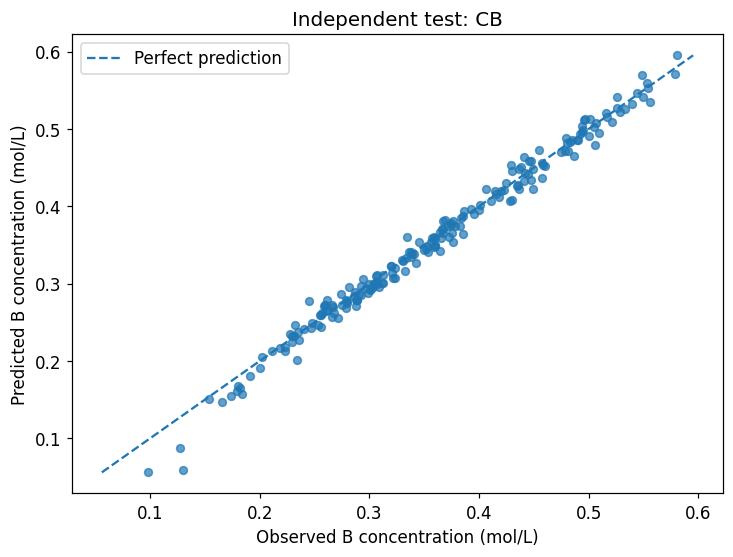

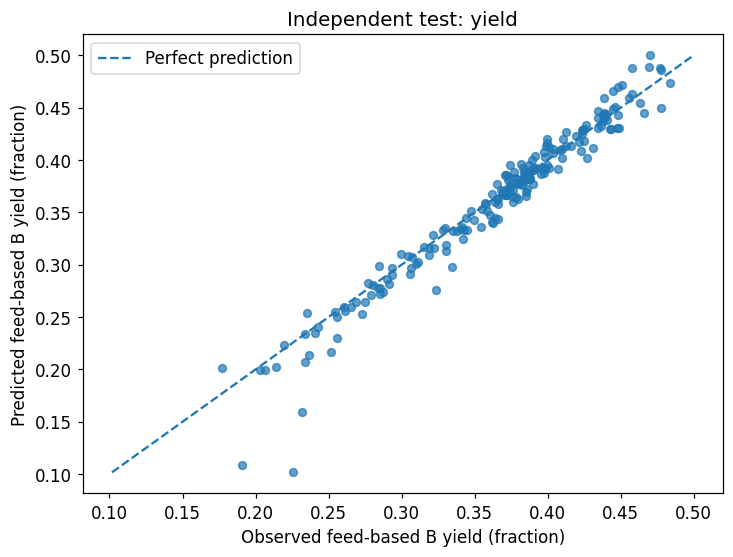

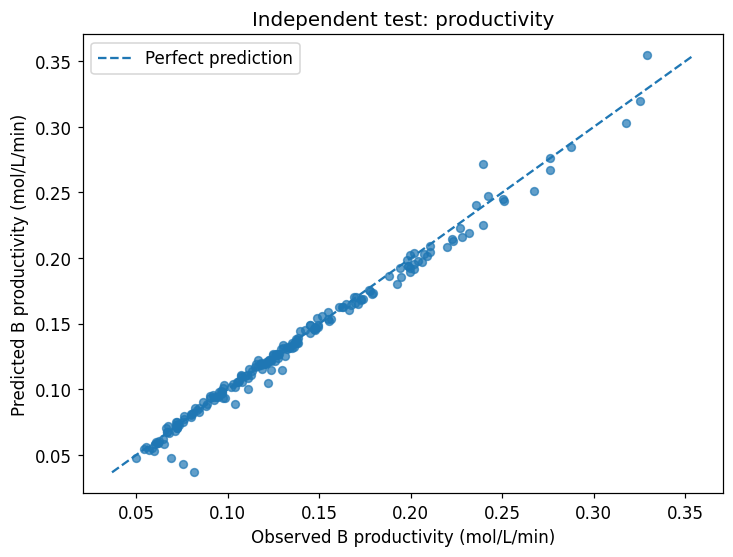

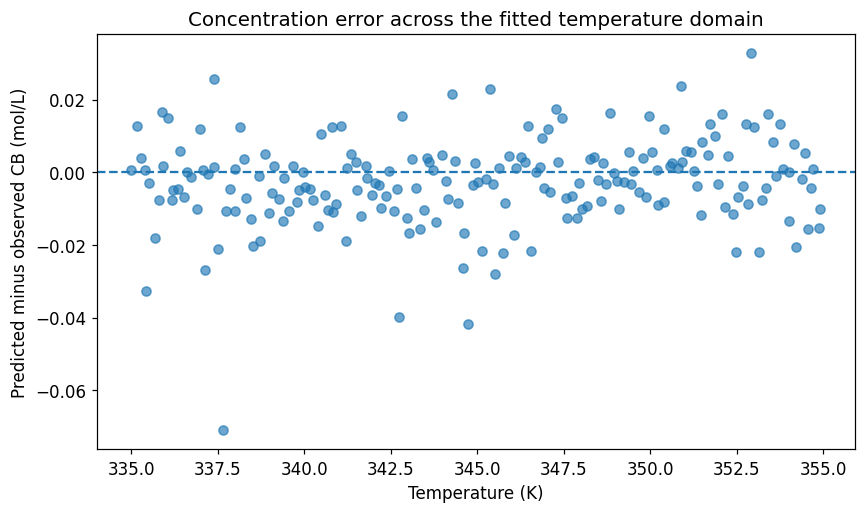

In [10]:
ptest = predict_responses(test[FEATURES])  # Obtain fixed predictions for the three test parity plots.
for j, name in enumerate(output_names):  # Plot each response separately rather than using small subplots.
    parity(test[name+'_observed'], ptest[:, j], 'Independent test: '+name, units[j], f'0{j+1}_parity_{name}')  # Show whether concentration accuracy carries through to the derived response.
fig, ax = plt.subplots(figsize=(8, 4.8))  # Create a dedicated residual-pattern diagnostic.
ax.scatter(test['temperature_K'], ptest[:, 0]-test['CB_observed'], alpha=0.65)  # Check whether concentration error changes systematically with temperature.
ax.axhline(0, linestyle='--')  # Mark the unbiased-error reference.
ax.set(xlabel='Temperature (K)', ylabel='Predicted minus observed CB (mol/L)', title='Concentration error across the fitted temperature domain')  # Identify the diagnostic variable and units.
save_plot(fig, '04_concentration_residuals')  # Save the test residual figure.

**Interpretation.** Systematic error can affect an operating recommendation even when a parity plot appears close to the diagonal. Examine the response and region that matter for the decision.

## 4. Stress-test the model and preserve physical identities
The temperature challenge is intentionally outside the fitting range. Do not use these outcomes to tune the model and still call it an untouched challenge.

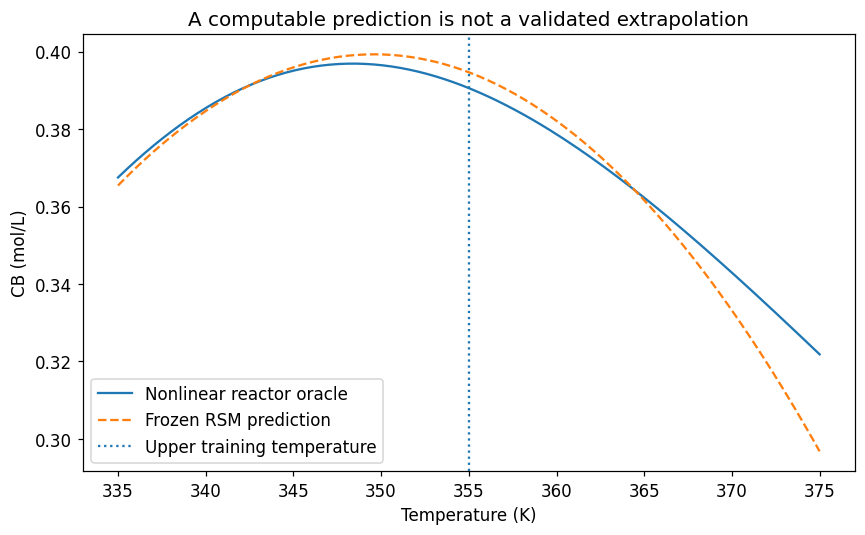

Independent-output identity RMS error (mol/L/min): 0.01135381593127808
Derived-output identity maximum error: 2.7755575615628914e-17


In [11]:
xline = np.tile(CENTRE, (160, 1))  # Hold residence time, feed concentration and catalyst concentration fixed.
xline[:, 0] = np.linspace(335, 375, len(xline))  # Extend the display from the fitted regime into the hotter challenge regime.
fig, ax = plt.subplots(figsize=(8, 5))  # Create one temperature-extrapolation comparison.
ax.plot(xline[:, 0], reactor(xline)[:, 1], label='Nonlinear reactor oracle')  # Plot the noise-free teaching response.
ax.plot(xline[:, 0], predict_responses(xline)[:, 0], '--', label='Frozen RSM prediction')  # Plot the learned polynomial outside as well as inside its fitting range.
ax.axvline(355, linestyle=':', label='Upper training temperature')  # Mark the explicit validation boundary.
ax.set(xlabel='Temperature (K)', ylabel='CB (mol/L)', title='A computable prediction is not a validated extrapolation')  # Emphasise the domain-of-validity lesson.
ax.legend()  # Distinguish the reference, surrogate and domain boundary.
save_plot(fig, '05_temperature_extrapolation')  # Save the regime comparison.
independent_y = sm.OLS(train['yield_observed'], design_matrix(train[FEATURES], degree)).fit()  # Fit yield separately only to illustrate an algebraic inconsistency risk.
independent_p = sm.OLS(train['productivity_observed'], design_matrix(train[FEATURES], degree)).fit()  # Fit productivity independently for the same diagnostic comparison.
yp = np.asarray(independent_y.predict(design_matrix(test[FEATURES], degree)))  # Predict yield using its separately estimated coefficients.
pp = np.asarray(independent_p.predict(design_matrix(test[FEATURES], degree)))  # Predict productivity using a different coefficient set.
identity_error = pp-test['feed_A_mol_L'].to_numpy()*yp/test['residence_time_min'].to_numpy()  # Measure disagreement with the exact response identity.
print('Independent-output identity RMS error (mol/L/min):', np.sqrt(np.mean(identity_error**2)))  # Quantify the artificial inconsistency.
print('Derived-output identity maximum error:', np.max(np.abs(ptest[:, 2]-test['feed_A_mol_L'].to_numpy()*ptest[:, 1]/test['residence_time_min'].to_numpy())))  # Verify that the primary-response method preserves the identity.

**Interpretation.** The comparison demonstrates why known algebra should be retained. It does not prove that the independent response fits are always less accurate on each individual output. Their predictions simply need not remain mutually consistent.

## 5. Visualise the operating trade-off
Hold feed concentration and catalyst concentration at their centres. Compare a yield slice with a productivity slice; their best regions need not coincide.

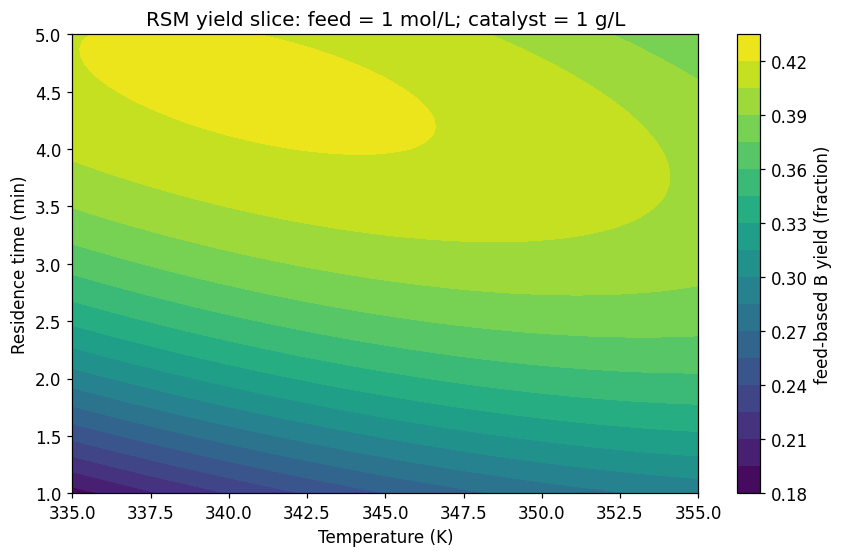

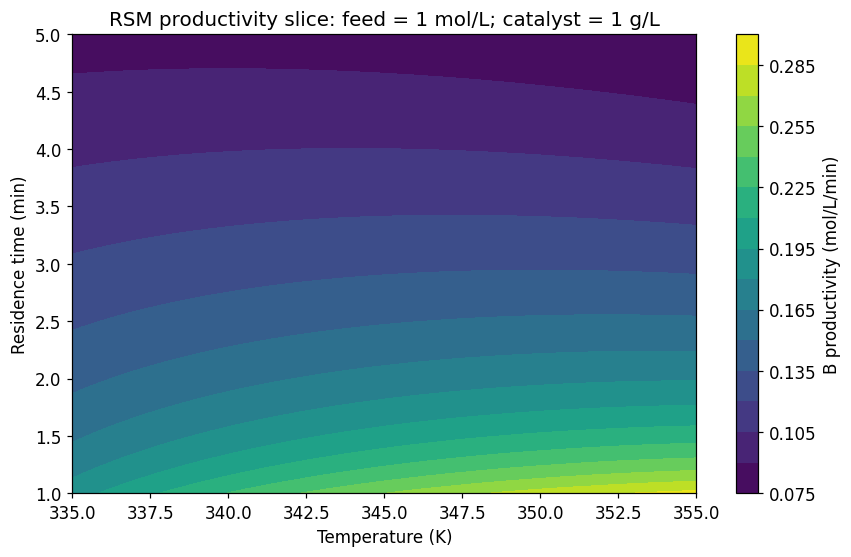

In [12]:
tg, rg = np.meshgrid(np.linspace(335, 355, 65), np.linspace(1, 5, 65))  # Form a temperature-residence-time grid inside the design range.
xgrid = np.column_stack((tg.ravel(), rg.ravel(), np.ones(tg.size), np.ones(tg.size)))  # Fix feed and catalyst concentrations at their centre values.
surfaces = predict_responses(xgrid)  # Evaluate the two engineering objectives from the same predicted concentration.
for j, name in [(1, 'yield'), (2, 'productivity')]:  # Display each objective at readable full-figure size.
    fig, ax = plt.subplots(figsize=(8, 5.2))  # Create an independent contour figure.
    contour = ax.contourf(tg, rg, surfaces[:, j].reshape(tg.shape), levels=18)  # Show how the predicted objective changes across operating conditions.
    fig.colorbar(contour, ax=ax, label=units[j])  # State the plotted response units.
    ax.set(xlabel='Temperature (K)', ylabel='Residence time (min)', title='RSM '+name+' slice: feed = 1 mol/L; catalyst = 1 g/L')  # Identify the two fixed inputs.
    save_plot(fig, '06_'+name+'_surface')  # Preserve the objective contour plot.

**Interpretation.** A longer residence time may improve conversion while reducing throughput per reactor volume. The full reaction sequence also consumes B, so the trade-off is not captured by residence time alone.

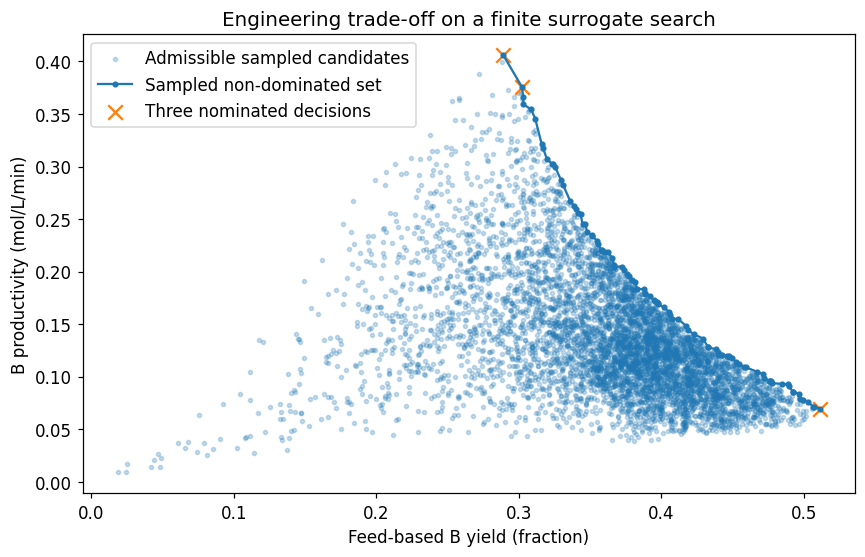

In [13]:
candidate_rng = np.random.default_rng(SEED+2001)  # Keep operating-point search independent of the experimental noise.
candidates = np.vstack((CENTRE, lhs(6000, BOUNDS, candidate_rng)))  # Search a finite candidate set inside the known operating box.
responses = predict_responses(candidates)  # Evaluate only surrogate outputs while forming the candidate decisions.
feasible = (responses[:, 0] >= 0) & (responses[:, 0] <= candidates[:, 2])  # Reject obvious non-physical B concentrations without clipping predictions.
candidates, responses = candidates[feasible], responses[feasible]  # Retain only algebraically admissible surrogate candidates.
order = np.argsort(-responses[:, 1], kind='stable')  # Sort candidates from highest to lowest predicted yield.
pareto_indices, best_productivity = [], -np.inf  # Start a two-objective non-dominance scan.
for i in order:  # Consider the yield-ordered candidates one by one.
    if responses[i, 2] > best_productivity:  # Retain candidates that improve productivity over every higher-yield option.
        pareto_indices.append(i)  # Store this non-dominated operating point.
        best_productivity = responses[i, 2]  # Update the productivity threshold for later candidates.
pareto_indices = np.asarray(pareto_indices)  # Convert the non-dominated indices into an array.
normalised = (responses[:, 1:]-responses[:, 1:].min(axis=0))/np.ptp(responses[:, 1:], axis=0)  # Put both objectives on comparable finite-candidate scales.
ideal_distance = np.linalg.norm(1-normalised[pareto_indices], axis=1)  # Calculate an equal-weight distance from the sampled ideal point.
compromise_index = pareto_indices[np.argmin(ideal_distance)]  # Select a stated preference-based compromise from the non-dominated candidates.
chosen = [np.argmax(responses[:, 1]), np.argmax(responses[:, 2]), compromise_index]  # Nominate yield, productivity and compromise choices using surrogate outputs only.
labels = ['Highest sampled yield', 'Highest sampled productivity', 'Equal-weight compromise']  # Describe these as finite-search recommendations, not proven global optima.
fig, ax = plt.subplots(figsize=(8, 5.2))  # Display the engineering trade-off separately from model-complexity trade-offs.
ax.scatter(responses[:, 1], responses[:, 2], s=7, alpha=0.25, label='Admissible sampled candidates')  # Show the attainable surrogate response cloud.
ax.plot(responses[pareto_indices, 1], responses[pareto_indices, 2], '-o', markersize=3, label='Sampled non-dominated set')  # Trace the candidate-level Pareto boundary.
ax.scatter(responses[chosen, 1], responses[chosen, 2], marker='x', s=90, label='Three nominated decisions')  # Highlight the decisions to verify next.
ax.set(xlabel='Feed-based B yield (fraction)', ylabel='B productivity (mol/L/min)', title='Engineering trade-off on a finite surrogate search')  # State the two competing engineering objectives.
ax.legend()  # Identify the candidate cloud and trade-off boundary.
save_plot(fig, '07_engineering_pareto')  # Save the system-level decision plot.

**Caution.** This is a finite sampled Pareto set, not a globally proven continuous frontier. Equal-weight distance is an explicit preference, not a universal definition of the best operating point. None of these decisions has yet been checked against the nonlinear reactor.

,temperature_K,residence_time_min,feed_A_mol_L,catalyst_g_L,predicted_yield,verified_yield,predicted_productivity,verified_productivity
Highest sampled yield,338.52665,3.75103,0.51064,1.42325,0.51091,0.48795,0.06955,0.06643
Highest sampled productivity,354.58000,1.00420,1.40949,1.35351,0.28914,0.31468,0.40584,0.44168
Equal-weight compromise,353.64760,1.05046,1.30617,1.47402,0.30216,0.33016,0.37572,0.41053


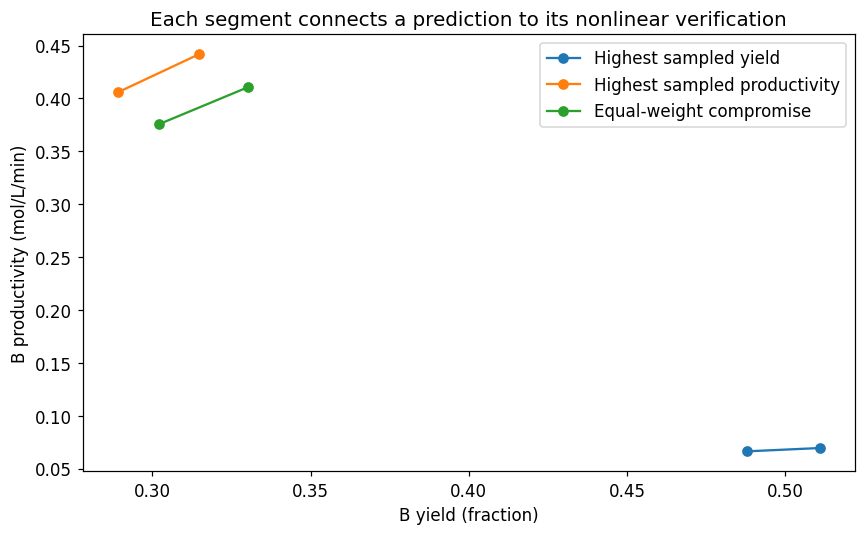

In [14]:
chosen_x = candidates[chosen]  # Retrieve only the three surrogate-selected operating conditions.
verified = reactor(chosen_x)  # Evaluate the nonlinear teaching reactor after the decisions have been nominated.
recommendations = pd.DataFrame(chosen_x, columns=FEATURES, index=labels)  # Label the three engineering recommendations.
recommendations['predicted_yield'], recommendations['verified_yield'] = responses[chosen, 1], verified[:, 3]  # Compare predicted and verified desired-product yields.
recommendations['predicted_productivity'], recommendations['verified_productivity'] = responses[chosen, 2], verified[:, 4]  # Compare predicted and verified reactor productivities.
display(recommendations.round(5))  # Show where surrogate errors affect the practical decision.
recommendations.to_csv(RESULTS/'verified_recommendations.csv')  # Preserve the nonlinear verification audit.
fig, ax = plt.subplots(figsize=(8, 5))  # Create a direct prediction-versus-verification decision figure.
for j, label in enumerate(labels):  # Draw one connecting segment for each nominated operating point.
    ax.plot([responses[chosen[j], 1], verified[j, 3]], [responses[chosen[j], 2], verified[j, 4]], '-o', label=label)  # Reveal the displacement from surrogate prediction to nonlinear verification.
ax.set(xlabel='B yield (fraction)', ylabel='B productivity (mol/L/min)', title='Each segment connects a prediction to its nonlinear verification')  # Explain the paired-point display.
ax.legend()  # Identify the three preference-based choices.
save_plot(fig, '08_decision_verification')  # Save the recommendation reliability figure.

**Engineering takeaway.** Use the surrogate to screen operating conditions, then verify recommendations with the original model or new experiments. A decision can be sensitive to small local errors even when global test accuracy is good.

## 6. Exercises and interpretation
**A · Locality:** narrow the temperature range and regenerate the entire experiment. Does a quadratic become a more adequate local approximation?

**B · Response dependence:** explain why independent Gaussian noise on all three outputs would contradict the stated measurement process.

**C · Preference:** change the relative weight of yield and productivity before inspecting new verification results. Explain which engineering priorities changed.

**D · Extrapolation:** identify the physical reason a polynomial should not be assumed valid above 355 K merely because it returns a finite number.

<details><summary><b>Instructor interpretation</b></summary>
The nonlinear generator combines Arrhenius sensitivity with reaction competition. A smaller domain often reduces approximation error, but new independent validation is still required. Yield and productivity share the concentration measurement and therefore share error. The algebraic response identity should be retained when possible. Engineering Pareto trade-offs concern yield and productivity; symbolic-regression Pareto trade-offs concern error and expression size. Neither frontier guarantees validity beyond the model's domain.
</details>

## Export your results
All figures, generated observations, model coefficients and prediction tables are saved in the case-specific results folder. Download the archive before disconnecting a temporary runtime. Use **File → Download → Download .ipynb** to retain your own comments and outputs.

In [15]:
archive = shutil.make_archive(str(RESULTS) + '_results', 'zip', RESULTS)  # Bundle this run's tables and figures into one archive.
display(FileLink(archive))  # Display a file link in notebook interfaces that support local downloads.
DOWNLOAD_RESULTS = False  # Set this switch to True to start a Colab browser download.
if DOWNLOAD_RESULTS:  # Avoid an unsolicited download during normal Run all execution.
    try:  # Use Colab's helper only in an environment where it exists.
        from google.colab import files  # Load Google's browser-download interface.
        files.download(archive)  # Copy the result archive to the learner's computer.
    except ImportError:  # Keep the same notebook usable in standard Jupyter.
        print('Use the link above or the notebook file browser.')  # Explain the non-Colab download route.
print('Core workflow finished: all displayed core results were calculated in this run.')  # Mark successful completion of the lesson.

/mnt/data/Colab_Teaching_Notebooks/results_02_rsm_selective_cstr_results.zip

Core workflow finished: all displayed core results were calculated in this run.


**Save your work.** Downloading the archive does not itself save edits to the notebook. Save both the `.ipynb` and the results archive.

## Sources and scope
All numerical chemical parameters and synthetic observations are teaching assumptions. The sources support the modelling concepts, not those invented parameter values.

- [Google Colab FAQ](https://research.google.com/colaboratory/faq.html)
- [NIST: response surface designs](https://www.itl.nist.gov/div898/handbook/pri/section3/pri336.htm)
- [statsmodels: ordinary least squares](https://www.statsmodels.org/stable/examples/notebooks/generated/ols.html)
- [SciPy: bounded nonlinear least squares](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.least_squares.html)
- [University of Michigan: multiple-reaction engineering](https://websites.umich.edu/~elements/6e/08chap/summary.html)
- [NIST: Box–Behnken designs](https://www.itl.nist.gov/div898/handbook/pri/section3/pri3362.htm)


**Verification boundary.** The supplied core workflow was executed in a clean local Python kernel and its outputs are saved. This is not a claim of execution in Google's hosted runtime. Any optional PySR section is disabled by default and excluded from the core execution check.